# 02 · Baselines and main model (XGBoost)

**Input:** `data/processed/windows_v2.parquet` + `feature_schema.json` from `01_eda.ipynb`.
**Goal:** a fair baseline table, then the main model (XGBoost) tuned on validation and tested once, with the deployment pieces we need later: a benign threshold, k-of-n smoothing, SHAP reasons, robustness splits, and local-only vs centralised (the reference for federated learning in notebook 03).

**Decisions carried from the EDA run**
| EDA result | Decision here |
|---|---|
| F51: ratios + rolling-3 add ≈ +3 pts val macro-F1; `seq_count_in_win` adds nothing | Use **32 features** = ML_23 (IAT in ms) + 4 ratios + 5 rolling. Drop `seq_count_in_win` (no sequence dependency at deployment) |
| F44: unweighted HistGBDT (0.883) > balanced (0.841); fewer false alarms (2.0 vs 19.5 /wall-clock h) | Default = **no class weighting**; test a mild √-balanced weighting on val only |
| F47 + confusion: exfiltration/ransomware are missed *as benign* (recall 0.61 / 0.53, precision > 0.9) | Tune a **benign threshold τ** on val: predict benign only when P(benign) ≥ τ |
| F48: 2.0 FP per wall-clock client-hour per window | Add **k-of-n smoothing** per client; report alerts/hour and time-to-detect |
| F52: polyglot detected from behaviour at F1 0.98 | Check it is not the 9,600-byte generator fingerprint (re-test without size features) |
| F08: labels.csv durations max ≈199 s | The two ≈8,600 s runs are fixed in this labels file; nothing to drop |

Runtime on a laptop CPU: roughly 15–30 min (mostly the XGBoost grid and seeds). Set `FAST = True` in the setup cell for a quick pass.

In [32]:
# 0 · Setup  (pip install xgboost  — once)
import os, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import beta
from sklearn.preprocessing import LabelEncoder, RobustScaler, QuantileTransformer
from sklearn.metrics import (f1_score, matthews_corrcoef, average_precision_score, roc_curve,
                             classification_report, confusion_matrix)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
import xgboost as xgb
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore")

FAST  = False                     # True = fewer seeds / smaller grid for a quick check
SEEDS = [0, 1, 2] if FAST else [0, 1, 2, 3, 4]
REPO  = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC  = REPO / "data" / "processed"
REP   = REPO / "reports" / "baselines"; REP.mkdir(parents=True, exist_ok=True)
MODELS = REPO / "models"; MODELS.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110
print("xgboost", xgb.__version__)

xgboost 3.4.1


In [33]:
import sys; sys.path.insert(0, str(REPO / "src"))
import tracking, mlflow

In [34]:
import importlib; importlib.reload(tracking)

<module 'tracking' from 'c:\\Users\\rashi\\Desktop\\VitalGate Project Code\\src\\tracking.py'>

In [35]:
print([f for f in dir(tracking) if not f.startswith("_")])

['ARTIFACTS', 'DATA_FILE', 'DATA_HASH', 'DB', 'Path', 'REPO', 'SESSION', 'contextmanager', 'data_hash', 'git_sha', 'hashlib', 'json', 'log_files', 'log_json', 'log_metrics', 'log_seed_summary', 'log_table', 'lru_cache', 'math', 'mlflow', 'pd', 'resume', 'run', 'runs', 'subprocess', 'time', 'use_experiment']


## 1 · Data and features

In [36]:
win = pd.read_parquet(PROC / "windows_v2.parquet")
schema = json.loads((PROC / "feature_schema.json").read_text(encoding="utf-8"))
RULE_CLASS = schema["rule_class"]
ROLL_BASE  = ["out_pkts", "out_bytes", "assoc_rq", "pdata_pkts", "mean_iat_ms"]
ROLL_FEATS = [f"{b}_roll3" for b in ROLL_BASE]
import features as FV                                                      # v3 feature builder (src/features.py)
FEATURES   = FV.FEATURES_V3                                                # 83 = 27 base + lag1/lag2 of all 27 + 2 time gaps
NN_FEATURES = [f for f in FEATURES if not f.startswith("n_calling_ae")]   # r≈0.998 with n_called_ae
SIZE_FEATS = [f for f in FEATURES if f.split("_lag")[0] in ("mean_pkt", "std_pkt", "out_bytes", "in_bytes", "bytes_per_pkt", "out_in_byte_ratio")]
assert not set(FEATURES) & set(schema["never_features"]), "a never-feature slipped in"
print(len(FEATURES), "features")

def add_rolling(frame, part_col):
    # v3: lag1/lag2 history + time gaps per client, never crossing a partition of part_col (name kept so later cells work unchanged)
    return FV.add_history(frame, part_col)

d = win[win["label_class"] != RULE_CLASS].reset_index(drop=True)     # polyglot = rule class
d = add_rolling(d, "split_run")
le = LabelEncoder().fit(d["label_class"]); CLS = list(le.classes_); K = len(CLS)
BEN, REC = CLS.index("benign"), CLS.index("recon")
y = le.transform(d["label_class"])
TR, VA, TE = [(d["split_run"] == p).values for p in ("train", "val", "test")]
print({p: int(m.sum()) for p, m in zip(("train", "val", "test"), (TR, VA, TE))}, "| classes:", CLS)

83 features
{'train': 37259, 'val': 5681, 'test': 7898} | classes: ['ae_bruteforce', 'assoc_flood', 'benign', 'exfiltration', 'malformed_pdu', 'ransomware_like', 'recon']


## 2 · Evaluation helpers

In [37]:
def wallclock_hours(frame, cap=60.0):
    t = frame.sort_values(["client_ip", "window_start"])
    return t.groupby("client_ip")["window_start"].diff().fillna(2.0).clip(upper=cap).sum() / 3600.0
HOURS = {"val": wallclock_hours(d[VA]), "test": wallclock_hours(d[TE])}

def decide(prob, tau=None):
    # tau=None -> argmax. Otherwise: benign only if P(benign) >= tau, else best attack class
    if tau is None:
        return prob.argmax(1)
    p = prob.copy(); p[:, BEN] = -1
    return np.where(prob[:, BEN] >= tau, BEN, p.argmax(1))

def metrics(yt, prob, part="test", tau=None):
    pred = decide(prob, tau)
    yb, score = (yt != BEN).astype(int), 1 - prob[:, BEN]
    fpr, tpr, _ = roc_curve(yb, score)
    keep = yt != REC
    pc = f1_score(yt, pred, labels=range(K), average=None, zero_division=0)
    out = dict(macro_F1=f1_score(yt, pred, average="macro"),
               macro_F1_no_recon=f1_score(yt[keep], pred[keep], labels=[i for i in range(K) if i != REC], average="macro"),
               MCC=matthews_corrcoef(yt, pred), PR_AUC=average_precision_score(yb, score),
               FPR_at_95TPR=fpr[np.argmax(tpr >= 0.95)],
               FP_per_wallclock_h=((pred != BEN) & (yt == BEN)).sum() / HOURS[part])
    out.update({f"F1_{c}": pc[i] for i, c in enumerate(CLS) if c in ("exfiltration", "ransomware_like")})
    return out

def summarise(rows):
    df = pd.DataFrame(rows)
    num = df.drop(columns="model").groupby(df["model"], sort=False)
    m, s = num.mean(), num.std().fillna(0)
    return m.round(3).astype(str) + " ± " + s.round(3).astype(str)

## 3 · Baselines on `split_run` (test reported once, mean ± std over seeds)

In [38]:
Xtr, Xva, Xte = d.loc[TR, FEATURES], d.loc[VA, FEATURES], d.loc[TE, FEATURES]
NN = FV.fill_for_nn(d[NN_FEATURES])                                       # LogReg / MLP cannot take NaN history
lin = RobustScaler().fit(np.log1p(NN[TR]))
L = lambda m: lin.transform(np.log1p(NN[m]))
qt = QuantileTransformer(output_distribution="normal", random_state=0).fit(NN[TR])
Q = lambda m: qt.transform(NN[m])

baselines = {
    "B0 Dummy (majority)":   (lambda s: DummyClassifier(strategy="most_frequent"), L),
    "B1 LogReg":             (lambda s: LogisticRegression(max_iter=3000, C=1.0), L),
    "B2 RandomForest":       (lambda s: RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=s), None),
    "B3 HistGBDT":           (lambda s: HistGradientBoostingClassifier(max_iter=400, early_stopping=True, random_state=s), None),
    "B4 MLP (128-64)":       (lambda s: MLPClassifier((128, 64), early_stopping=True, max_iter=200, random_state=s), Q),
}
rows, t0 = [], time.time()
for name, (make, tf) in baselines.items():
    seeds = SEEDS if name not in ("B0 Dummy (majority)", "B1 LogReg") else [0]
    with tracking.run(name, params={"n_features": len(NN_FEATURES if tf is not None else FEATURES),
                                    "input": "raw" if tf is None else ("log1p+robust" if tf is L else "quantile")},
                      tags={"stage": "baseline", "split": "split_run/test"}):
        per_seed = []
        for s in seeds:
            m = make(s)
            if tf is None: m.fit(Xtr, y[TR]); p = m.predict_proba(Xte)
            else:          m.fit(tf(TR), y[TR]); p = m.predict_proba(tf(TE))
            r = metrics(y[TE], p); per_seed.append(r); rows.append(dict(model=name, **r))
            with tracking.run(f"{name} · seed {s}", params={"seed": s}, tags={"stage": "seed"}, nested=True):
                tracking.log_metrics(r)
        tracking.log_seed_summary(per_seed)
    print(f"{name}: done ({time.time()-t0:.0f}s)")
BASE = summarise(rows); display(BASE)

B0 Dummy (majority): done (1s)
B1 LogReg: done (3s)
B2 RandomForest: done (50s)
B3 HistGBDT: done (69s)
B4 MLP (128-64): done (112s)


,macro_F1,macro_F1_no_recon,MCC,PR_AUC,FPR_at_95TPR,FP_per_wallclock_h,F1_exfiltration,F1_ransomware_like
model,,,,,,,,
B0 Dummy (majority),0.117 ± 0.0,0.141 ± 0.0,0.0 ± 0.0,0.303 ± 0.0,1.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
B1 LogReg,0.917 ± 0.0,0.904 ± 0.0,0.926 ± 0.0,0.986 ± 0.0,0.026 ± 0.0,0.307 ± 0.0,0.687 ± 0.0,0.828 ± 0.0
B2 RandomForest,0.948 ± 0.001,0.94 ± 0.001,0.951 ± 0.001,0.994 ± 0.0,0.005 ± 0.0,0.485 ± 0.015,0.831 ± 0.004,0.86 ± 0.004
B3 HistGBDT,0.95 ± 0.001,0.942 ± 0.002,0.956 ± 0.001,0.995 ± 0.0,0.002 ± 0.0,0.307 ± 0.056,0.825 ± 0.005,0.867 ± 0.007
B4 MLP (128-64),0.935 ± 0.003,0.925 ± 0.004,0.939 ± 0.003,0.991 ± 0.001,0.011 ± 0.001,0.792 ± 0.328,0.797 ± 0.015,0.819 ± 0.007


## 4 · Main model: XGBoost
Small grid on **validation** (depth × learning rate × weighting), early stopping on val, then the chosen setting is re-run with all seeds and scored on test.
Weighting options: `none` (EDA winner) and `sqrt` (√ of inverse class frequency — a mild middle ground).

In [39]:
def sample_weights(yy, mode):
    if mode == "none": return None
    cnt = np.bincount(yy, minlength=K); w = (cnt.max() / np.maximum(cnt, 1)) ** 0.5
    return w[yy]

def make_xgb(depth, lr, seed, n_est=2000):
    return xgb.XGBClassifier(n_estimators=n_est, max_depth=depth, learning_rate=lr, subsample=0.8, colsample_bytree=0.8,
                             min_child_weight=1, tree_method="hist", objective="multi:softprob", eval_metric="mlogloss",
                             early_stopping_rounds=50, random_state=seed, n_jobs=-1)

def fit_xgb(cfg, seed, Xa, ya, Xv, yv):
    m = make_xgb(cfg["depth"], cfg["lr"], seed)
    m.fit(Xa, ya, sample_weight=sample_weights(ya, cfg["weights"]), eval_set=[(Xv, yv)], verbose=False)
    return m

grid = [dict(depth=dp, lr=lr, weights=w) for dp in ([6] if FAST else [4, 6, 8]) for lr in [0.05, 0.1] for w in ["none", "sqrt"]]
g_rows = []
with tracking.run("XGBoost grid", tags={"stage": "xgb_grid", "split": "split_run/val"}):
    for cfg in grid:
        m = fit_xgb(cfg, 0, Xtr, y[TR], Xva, y[VA])
        r = metrics(y[VA], m.predict_proba(Xva), "val")
        g_rows.append(dict(**cfg, best_iter=m.best_iteration, **{k: round(v, 4) for k, v in r.items()}))
        with tracking.run(f"xgb d{cfg['depth']} lr{cfg['lr']} w{cfg['weights']}", params=cfg, tags={"stage": "xgb_grid_cfg"}, nested=True):
            tracking.log_metrics({**r, "best_iter": m.best_iteration})
G = pd.DataFrame(g_rows).sort_values("macro_F1", ascending=False); display(G)
BEST = {k: G.iloc[0][k] for k in ("depth", "lr", "weights")}
BEST["depth"] = int(BEST["depth"]); BEST["lr"] = float(BEST["lr"])
print("chosen:", BEST)

,depth,lr,weights,best_iter,macro_F1,macro_F1_no_recon,MCC,PR_AUC,FPR_at_95TPR,FP_per_wallclock_h,F1_exfiltration,F1_ransomware_like
11,8,0.10,sqrt,80,0.9580,0.9510,0.9618,0.9974,0.0016,0.3247,0.8518,0.8854
9,8,0.05,sqrt,162,0.9577,0.9506,0.9611,0.9973,0.0019,0.4175,0.8545,0.8803
1,4,0.05,sqrt,475,0.9575,0.9505,0.9602,0.9966,0.0027,0.7886,0.8591,0.8811
5,6,0.05,sqrt,218,0.9569,0.9497,0.9596,0.9968,0.0033,0.6494,0.8584,0.8763
3,4,0.10,sqrt,232,0.9556,0.9482,0.9583,0.9964,0.0033,0.9278,0.8539,0.8748
7,6,0.10,sqrt,119,0.9555,0.9481,0.9589,0.9970,0.0036,0.7422,0.8460,0.8768
6,6,0.10,none,118,0.9527,0.9448,0.9561,0.9974,0.0022,0.1856,0.8443,0.8700
10,8,0.10,none,87,0.9525,0.9446,0.9558,0.9976,0.0014,0.1392,0.8434,0.8689
4,6,0.05,none,222,0.9517,0.9436,0.9552,0.9972,0.0027,0.2319,0.8333,0.8696
2,4,0.10,none,199,0.9509,0.9427,0.9546,0.9970,0.0025,0.1856,0.8404,0.8608


chosen: {'depth': 8, 'lr': 0.1, 'weights': 'sqrt'}


In [40]:
xgb_models, xgb_rows, P_VA, P_TE = [], [], [], []
with tracking.run("XGBoost final", params={**BEST, "n_features": len(FEATURES), "features": FEATURES,
                                            "early_stopping": 50, "subsample": 0.8, "colsample_bytree": 0.8},
                  tags={"stage": "final", "split": "split_run/test", "model": "xgboost"}) as FINAL:
    for s in SEEDS:
        m = fit_xgb(BEST, s, Xtr, y[TR], Xva, y[VA]); xgb_models.append(m)
        P_VA.append(m.predict_proba(Xva)); P_TE.append(m.predict_proba(Xte))
        r = metrics(y[TE], P_TE[-1]); xgb_rows.append(dict(model="XGBoost (argmax)", **r))
        with tracking.run(f"XGBoost final · seed {s}", params={"seed": s, "best_iter": m.best_iteration},
                          tags={"stage": "seed"}, nested=True):
            tracking.log_metrics(r)
    tracking.log_seed_summary([{k: v for k, v in r.items() if k != "model"} for r in xgb_rows])
FINAL_ID = FINAL.info.run_id
P_VA, P_TE = np.mean(P_VA, 0), np.mean(P_TE, 0)
RESULTS = pd.concat([BASE, summarise(xgb_rows)]); display(RESULTS)


,macro_F1,macro_F1_no_recon,MCC,PR_AUC,FPR_at_95TPR,FP_per_wallclock_h,F1_exfiltration,F1_ransomware_like
model,,,,,,,,
B0 Dummy (majority),0.117 ± 0.0,0.141 ± 0.0,0.0 ± 0.0,0.303 ± 0.0,1.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
B1 LogReg,0.917 ± 0.0,0.904 ± 0.0,0.926 ± 0.0,0.986 ± 0.0,0.026 ± 0.0,0.307 ± 0.0,0.687 ± 0.0,0.828 ± 0.0
B2 RandomForest,0.948 ± 0.001,0.94 ± 0.001,0.951 ± 0.001,0.994 ± 0.0,0.005 ± 0.0,0.485 ± 0.015,0.831 ± 0.004,0.86 ± 0.004
B3 HistGBDT,0.95 ± 0.001,0.942 ± 0.002,0.956 ± 0.001,0.995 ± 0.0,0.002 ± 0.0,0.307 ± 0.056,0.825 ± 0.005,0.867 ± 0.007
B4 MLP (128-64),0.935 ± 0.003,0.925 ± 0.004,0.939 ± 0.003,0.991 ± 0.001,0.011 ± 0.001,0.792 ± 0.328,0.797 ± 0.015,0.819 ± 0.007
XGBoost (argmax),0.954 ± 0.001,0.947 ± 0.001,0.96 ± 0.001,0.996 ± 0.0,0.002 ± 0.0,0.424 ± 0.054,0.837 ± 0.002,0.879 ± 0.004


## 5 · Benign threshold τ (fixes attacks missed as benign)
Pick τ on **val** to maximise macro-F1 with a cap on false alarms (≤ 1.5× the argmax FP rate), then apply the frozen τ to test.

argmax val macro-F1=0.9567, FP/h=0.46  ->  tau = None


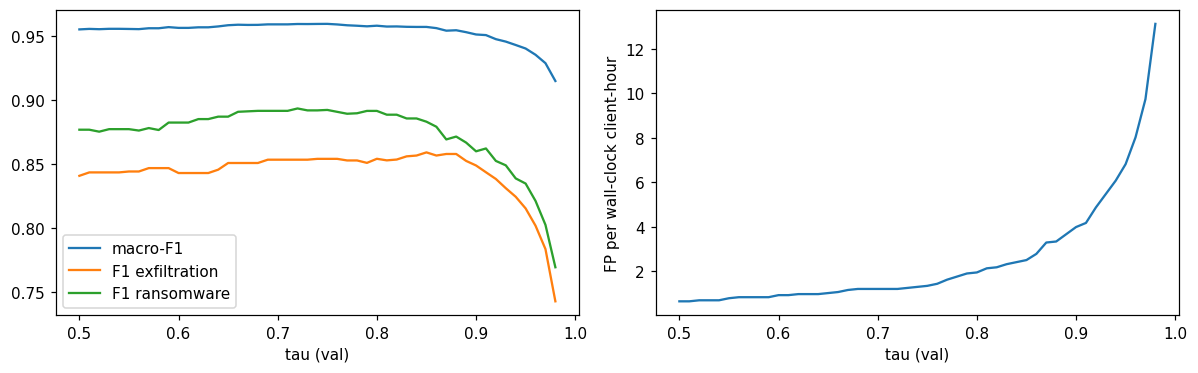

,macro_F1,macro_F1_no_recon,MCC,PR_AUC,FPR_at_95TPR,FP_per_wallclock_h,F1_exfiltration,F1_ransomware_like
argmax,0.954,0.946,0.96,0.996,0.001,0.335,0.836,0.876
tau=None,0.954,0.946,0.96,0.996,0.001,0.335,0.836,0.876


                 precision    recall  f1-score   support

  ae_bruteforce      0.996     0.992     0.994       490
    assoc_flood      1.000     1.000     1.000       446
         benign      0.981     0.998     0.990      5506
   exfiltration      0.937     0.755     0.836       294
  malformed_pdu      0.997     0.970     0.984       369
ransomware_like      0.904     0.849     0.876       378
          recon      1.000     1.000     1.000       415

       accuracy                          0.980      7898
      macro avg      0.974     0.938     0.954      7898
   weighted avg      0.980     0.980     0.980      7898



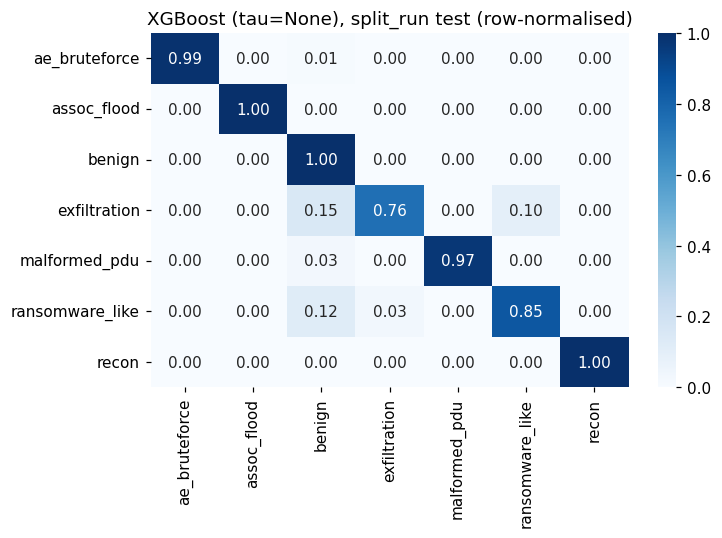

In [41]:
base_fp = metrics(y[VA], P_VA, "val")["FP_per_wallclock_h"]
taus = np.round(np.arange(0.50, 0.99, 0.01), 2)
curve = pd.DataFrame([dict(tau=t, **metrics(y[VA], P_VA, "val", t)) for t in taus])
ok = curve[curve["FP_per_wallclock_h"] <= max(1.5 * base_fp, base_fp + 0.5)]
argmax_f1 = metrics(y[VA], P_VA, "val")["macro_F1"]
TAU = float(ok.loc[ok["macro_F1"].idxmax(), "tau"]) if len(ok) else None
if TAU is not None and ok["macro_F1"].max() < argmax_f1 + 0.002:
    TAU = None                         # no real gain on val -> keep plain argmax
print(f"argmax val macro-F1={argmax_f1:.4f}, FP/h={base_fp:.2f}  ->  tau = {TAU}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(curve["tau"], curve["macro_F1"], label="macro-F1"); ax[0].plot(curve["tau"], curve["F1_exfiltration"], label="F1 exfiltration")
ax[0].plot(curve["tau"], curve["F1_ransomware_like"], label="F1 ransomware"); ax[0].set_xlabel("tau (val)"); ax[0].legend()
ax[1].plot(curve["tau"], curve["FP_per_wallclock_h"]); ax[1].set_xlabel("tau (val)"); ax[1].set_ylabel("FP per wall-clock client-hour")
if TAU: [a.axvline(TAU, ls="--", c="grey") for a in ax]
plt.tight_layout(); plt.savefig(REP / "tau_curve.png"); plt.show()

cmp = pd.DataFrame({"argmax": metrics(y[TE], P_TE), f"tau={TAU}": metrics(y[TE], P_TE, "test", TAU)}).T.round(3); display(cmp)
PRED_TE = decide(P_TE, TAU)
print(classification_report(y[TE], PRED_TE, labels=range(K), target_names=CLS, digits=3, zero_division=0))
cm = confusion_matrix(y[TE], PRED_TE, labels=range(K), normalize="true")
plt.figure(figsize=(7, 5)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLS, yticklabels=CLS)
plt.title(f"XGBoost (tau={TAU}), split_run test (row-normalised)"); plt.tight_layout(); plt.savefig(REP / "confusion_xgb_tau.png"); plt.show()
with tracking.resume(FINAL_ID):
    mlflow.log_param("tau", TAU)
    tracking.log_metrics(metrics(y[TE], P_TE, "test", TAU), prefix="decision_")
    tracking.log_files(REP / "tau_curve.png", REP / "confusion_xgb_tau.png")

## 6 · Temporal smoothing (deployment view)
Per client, raise an **alert** when ≥ k of the last n windows are flagged as attack (windows more than 60 s apart start a new streak).
Reported: false-alert windows and alert *episodes* per wall-clock client-hour on benign traffic, run detection with exact 95% CIs, and time to detect.

In [42]:
def smooth(frame, flag, k, n, gap=60):
    f = frame[["client_ip", "window_start"]].assign(flag=flag.astype(int)).sort_values(["client_ip", "window_start"])
    new = f.groupby("client_ip")["window_start"].diff().fillna(1e9) > gap
    seg = new.cumsum()
    f["alert"] = f.groupby(seg)["flag"].transform(lambda s: s.rolling(n, min_periods=1).sum() >= k)
    f["episode_start"] = f["alert"] & ~f.groupby(seg)["alert"].shift(1, fill_value=False)
    return f.sort_index()

def clopper(kk, nn, a=0.05):
    lo = beta.ppf(a / 2, kk, nn - kk + 1) if kk > 0 else 0.0
    hi = beta.ppf(1 - a / 2, kk + 1, nn - kk) if kk < nn else 1.0
    return f"[{lo*100:.0f}, {hi*100:.0f}]"

test = d[TE].reset_index(drop=True); yt = y[TE]
flag = PRED_TE != BEN
rows = []
for k, n in [(1, 1), (2, 3), (3, 5)]:
    s = smooth(test, flag, k, n); ben = yt == BEN
    atk = test.assign(alert=s["alert"].values, ws=test["window_start"])[yt != BEN]
    per_run = atk.groupby("attack_run").agg(cls=("label_class", "first"), hit=("alert", "any"),
                                           t0=("ws", "min"), t_hit=("ws", lambda w: w[atk.loc[w.index, "alert"]].min() if atk.loc[w.index, "alert"].any() else np.nan))
    per_run["ttd"] = per_run["t_hit"] - per_run["t0"] + 2
    rows.append(dict(rule=f"{k}-of-{n}", alert_windows_per_h=round((s["alert"].values & ben).sum() / HOURS["test"], 2),
                     episodes_per_h=round((s["episode_start"].values & ben).sum() / HOURS["test"], 2),
                     runs_detected=f"{int(per_run['hit'].sum())}/{len(per_run)} {clopper(int(per_run['hit'].sum()), len(per_run))}",
                     median_TTD_s=round(per_run["ttd"].median(), 1), p90_TTD_s=round(per_run["ttd"].quantile(0.9), 1)))
    if (k, n) == (2, 3):
        by_cls = per_run.groupby("cls").agg(runs=("hit", "size"), detected=("hit", "sum"), median_TTD_s=("ttd", "median"))
SMOOTH = pd.DataFrame(rows).set_index("rule"); display(SMOOTH)
with tracking.resume(FINAL_ID):
    for rule, r in SMOOTH.iterrows():
        det, n = r["runs_detected"].split()[0].split("/")
        tag = rule.replace("-", "")
        tracking.log_metrics({"alert_windows_per_h": r["alert_windows_per_h"], "episodes_per_h": r["episodes_per_h"],
                              "run_recall": int(det) / int(n), "median_TTD_s": r["median_TTD_s"], "p90_TTD_s": r["p90_TTD_s"]},
                             prefix=f"smooth_{tag}_")
print("2-of-3 per class:"); display(by_cls)

,alert_windows_per_h,episodes_per_h,runs_detected,median_TTD_s,p90_TTD_s
rule,,,,,
1-of-1,0.33,0.22,"108/108 [97, 100]",2.0,6.0
2-of-3,0.25,0.03,"108/108 [97, 100]",4.0,12.6
3-of-5,0.31,0.00,"105/108 [92, 99]",6.0,20.0


2-of-3 per class:


,runs,detected,median_TTD_s
cls,,,
ae_bruteforce,18,18,4.0
assoc_flood,18,18,4.0
exfiltration,18,18,9.0
malformed_pdu,18,18,4.0
ransomware_like,18,18,4.0
recon,18,18,4.0


## 7 · Explanations (exact TreeSHAP from XGBoost, no extra package)

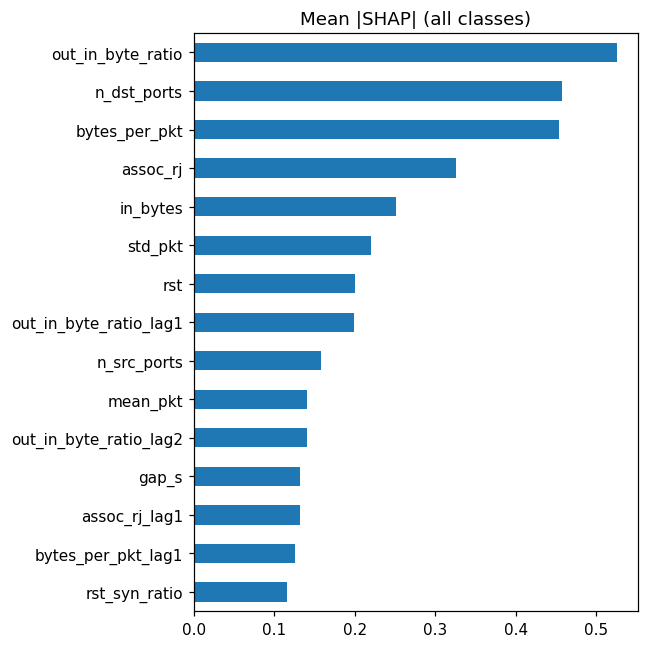

ae_bruteforce      assoc_rj, assoc_rj_lag1, in_bytes, assoc_rj_la...
assoc_flood        bytes_per_pkt, n_src_ports, mean_pkt, bytes_pe...
benign             out_in_byte_ratio, bytes_per_pkt, out_in_byte_...
exfiltration       out_in_byte_ratio, out_in_byte_ratio_lag2, out...
malformed_pdu      rst, bytes_per_pkt, out_in_byte_ratio, rst_lag...
ransomware_like    mean_pkt, in_bytes_lag2, in_bytes, bytes_per_p...
recon              n_dst_ports, rst_syn_ratio, bytes_per_pkt, rst...
Name: top-5 features pushing towards the class, dtype: str

In [43]:
m0 = xgb_models[0]
sample = Xte.sample(min(3000, len(Xte)), random_state=0)
contrib = m0.get_booster().predict(xgb.DMatrix(sample), pred_contribs=True)   # (n, K, F+1) for multiclass
contrib = np.asarray(contrib).reshape(len(sample), K, len(FEATURES) + 1)[:, :, :-1]
glob = pd.Series(np.abs(contrib).mean((0, 1)), index=FEATURES).sort_values(ascending=False)
plt.figure(figsize=(6, 6)); glob.head(15)[::-1].plot.barh(); plt.title("Mean |SHAP| (all classes)")
plt.tight_layout(); plt.savefig(REP / "shap_global.png"); plt.show()

ys = le.transform(d.loc[sample.index, "label_class"])
top = {}
for i, c in enumerate(CLS):
    mask = ys == i
    if mask.sum() == 0: continue
    top[c] = ", ".join(pd.Series(contrib[mask, i, :].mean(0), index=FEATURES).sort_values(ascending=False).head(5).index)
TOP = pd.Series(top, name="top-5 features pushing towards the class"); display(TOP)
with tracking.resume(FINAL_ID):
    tracking.log_files(REP / "shap_global.png")
    tracking.log_table(glob.rename("mean_abs_shap").to_frame(), "shap_global.csv")
    tracking.log_table(TOP.to_frame(), "shap_top5_per_class.csv")

## 8 · Polyglot check: behaviour or generator fingerprint?

In [44]:
p = add_rolling(win.reset_index(drop=True), "split_run")
ptr, pva, pte = [(p["split_run"] == s).values for s in ("train", "val", "test")]
yp = (p["label_class"] == RULE_CLASS).astype(int).values
res = {}
for name, cols in {"all 32 features": FEATURES, "without size/bytes features": [f for f in FEATURES if f not in SIZE_FEATS]}.items():
    mm = xgb.XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.1, tree_method="hist", n_jobs=-1, random_state=0)
    mm.fit(p.loc[ptr, cols], yp[ptr])
    res[name] = round(f1_score(yp[pte], mm.predict(p.loc[pte, cols])), 3)
display(pd.Series(res, name="polyglot-vs-rest F1 (split_run test)"))
with tracking.run("Polyglot behaviour check", tags={"stage": "polyglot_check", "split": "split_run/test"}):
    tracking.log_metrics({"F1_all_features": res["all 32 features"], "F1_without_size": res["without size/bytes features"]})
print("If F1 collapses without size features, the ML signal was the 9,600-byte fingerprint -> keep polyglot rule-only.")

all 32 features                0.986
without size/bytes features    0.978
Name: polyglot-vs-rest F1 (split_run test), dtype: float64

If F1 collapses without size features, the ML signal was the 9,600-byte fingerprint -> keep polyglot rule-only.


## 9 · Robustness splits (rolling recomputed inside each protocol)

In [45]:
def run_protocol(part_col, tr_mask_fn, te_mask_fn):
    f = add_rolling(win[win["label_class"] != RULE_CLASS].reset_index(drop=True), part_col)
    yy = le.transform(f["label_class"]); tr, te = tr_mask_fn(f), te_mask_fn(f)
    va = (f[part_col] == "val").values if part_col.startswith("split") else tr & False
    if va.sum() == 0:   # no val partition -> hold out 10% of train runs for early stopping
        rng = np.random.default_rng(0); grp = f["attack_run"].where(f["attack_run"] != "", f["client_ip"])
        hold = set(rng.choice(grp[tr].unique(), max(1, int(0.1 * grp[tr].nunique())), replace=False))
        va = tr & grp.isin(hold).values; tr = tr & ~va
    m = fit_xgb(BEST, 0, f.loc[tr, FEATURES], yy[tr], f.loc[va, FEATURES], yy[va])
    pr = m.predict_proba(f.loc[te, FEATURES])
    HOURS["tmp"] = wallclock_hours(f[te])
    r = metrics(yy[te], pr, "tmp", TAU)
    return {k: round(v, 3) for k, v in r.items()}

def run_protocol_logged(label, *args):
    with tracking.run(f"XGBoost · {label}", params={**BEST, "tau": TAU}, tags={"stage": "robustness", "protocol": label}):
        r = run_protocol(*args); tracking.log_metrics(r)
    return r

camps = sorted(win.loc[win["campaign_filled"].astype(str) != "", "campaign_filled"].unique())[:2]
ROB = pd.DataFrame({
    "split_run (reference)": run_protocol_logged("split_run (reference)", "split_run", lambda f: (f["split_run"] == "train").values, lambda f: (f["split_run"] == "test").values),
    "split_site (unseen site)": run_protocol_logged("split_site (unseen site)", "split_site", lambda f: (f["split_site"] == "train").values, lambda f: (f["split_site"] == "test").values),
    "split_time": run_protocol_logged("split_time", "split_time", lambda f: (f["split_time"] == "train").values, lambda f: (f["split_time"] == "test").values),
    f"campaign {camps[0]} -> {camps[1]}": run_protocol_logged(f"campaign {camps[0]} -> {camps[1]}", "campaign_filled", lambda f: (f["campaign_filled"] == camps[0]).values, lambda f: (f["campaign_filled"] == camps[1]).values),
    f"campaign {camps[1]} -> {camps[0]}": run_protocol_logged(f"campaign {camps[1]} -> {camps[0]}", "campaign_filled", lambda f: (f["campaign_filled"] == camps[1]).values, lambda f: (f["campaign_filled"] == camps[0]).values),
}).T
display(ROB[["macro_F1", "macro_F1_no_recon", "F1_exfiltration", "F1_ransomware_like", "FP_per_wallclock_h"]])

,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h
split_run (reference),0.954,0.946,0.834,0.878,0.418
split_site (unseen site),0.952,0.945,0.838,0.889,0.901
split_time,0.910,0.895,0.704,0.779,1.972
campaign run_0001 -> run_0002,0.850,0.828,0.527,0.604,0.279
campaign run_0002 -> run_0001,0.923,0.910,0.580,0.938,6.347


## 10 · Local-only vs centralised (reference for federated learning)
Each site trains only on its own `split_run` train windows; all models are scored on the full `split_run` test. Federated XGBoost (notebook 03) must land between *best local* and *centralised*.

In [46]:
loc_rows = []
for site in sorted(d["site"].unique()):
    sm = (d["site"] == site).values
    with tracking.run(f"XGBoost · local-only site {site}", params={**BEST, "tau": TAU, "train_site": site},
                      tags={"stage": "local_vs_central", "setting": "local", "site": site}):
        m = fit_xgb(BEST, 0, d.loc[TR & sm, FEATURES], y[TR & sm], d.loc[VA & sm, FEATURES], y[VA & sm])
        r = metrics(y[TE], m.predict_proba(Xte), "test", TAU); tracking.log_metrics(r)
    loc_rows.append(dict(setting=f"local-only site {site}", **{k: round(v, 3) for k, v in r.items()}))
with tracking.run("XGBoost · centralised", params={**BEST, "tau": TAU}, tags={"stage": "local_vs_central", "setting": "centralised"}):
    cent = metrics(y[TE], fit_xgb(BEST, 0, Xtr, y[TR], Xva, y[VA]).predict_proba(Xte), "test", TAU); tracking.log_metrics(cent)
loc_rows.append(dict(setting="centralised (all sites)", **{k: round(v, 3) for k, v in cent.items()}))
LOCAL = pd.DataFrame(loc_rows).set_index("setting")
display(LOCAL[["macro_F1", "macro_F1_no_recon", "F1_exfiltration", "F1_ransomware_like", "FP_per_wallclock_h"]])

,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h
setting,,,,,
local-only site A,0.947,0.939,0.817,0.865,0.446
local-only site B,0.928,0.922,0.756,0.844,1.674
local-only site C,0.945,0.936,0.814,0.866,0.502
centralised (all sites),0.954,0.946,0.834,0.878,0.418


## 11 · Save

In [47]:
xgb_models[0].save_model(MODELS / "xgb_split_run.json")
config = dict(feature_version=FV.FEATURE_VERSION, features=FEATURES, classes=CLS, best_params=BEST, tau=TAU, smoothing="2-of-3, 60 s gap",
              rolling=dict(base=ROLL_BASE, window=3, causal=True), rule_class=RULE_CLASS, seeds=SEEDS)
(MODELS / "xgb_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
RESULTS.to_csv(REP / "baselines_test.csv", encoding="utf-8-sig")
G.to_csv(REP / "xgb_grid_val.csv", index=False, encoding="utf-8-sig")
SMOOTH.to_csv(REP / "smoothing_test.csv", encoding="utf-8-sig")
ROB.to_csv(REP / "robustness.csv", encoding="utf-8-sig")
LOCAL.to_csv(REP / "local_vs_central.csv", encoding="utf-8-sig")
with tracking.resume(FINAL_ID):
    tracking.log_files(MODELS / "xgb_split_run.json", MODELS / "xgb_config.json")
print("saved to", MODELS, "and", REP)
display(RESULTS[["macro_F1", "macro_F1_no_recon", "F1_exfiltration", "F1_ransomware_like", "FP_per_wallclock_h"]])

saved to c:\Users\rashi\Desktop\VitalGate Project Code\models and c:\Users\rashi\Desktop\VitalGate Project Code\reports\baselines


,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h
model,,,,,
B0 Dummy (majority),0.117 ± 0.0,0.141 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
B1 LogReg,0.917 ± 0.0,0.904 ± 0.0,0.687 ± 0.0,0.828 ± 0.0,0.307 ± 0.0
B2 RandomForest,0.948 ± 0.001,0.94 ± 0.001,0.831 ± 0.004,0.86 ± 0.004,0.485 ± 0.015
B3 HistGBDT,0.95 ± 0.001,0.942 ± 0.002,0.825 ± 0.005,0.867 ± 0.007,0.307 ± 0.056
B4 MLP (128-64),0.935 ± 0.003,0.925 ± 0.004,0.797 ± 0.015,0.819 ± 0.007,0.792 ± 0.328
XGBoost (argmax),0.954 ± 0.001,0.947 ± 0.001,0.837 ± 0.002,0.879 ± 0.004,0.424 ± 0.054


## 12 · Combined models (soft voting)
**Question:** do two models working together beat XGBoost alone?

**How:** each model outputs class probabilities for a window. The ensemble averages them, `P = w · P_A + (1 − w) · P_B`, and predicts the class with the highest averaged probability.
- The weight `w` of the first model is chosen on **validation** only (0.0 to 1.0 in steps of 0.1), then frozen and applied to test.
- `w = 1.0` means the second model added nothing on validation.
- Every combination is run with the same 5 seeds as the baselines (mean ± std).

| Combination | Why test it |
|---|---|
| XGB + RF | boosting + bagging: different ways of building trees |
| XGB + HistGBDT | two boosting models: checks whether averaging similar models helps |
| XGB + MLP | tree + neural network: the most different pair, best chance of fixing different errors |
| RF + HistGBDT | the best non-XGBoost pair, for comparison |
| All 4 (equal average) | upper bound of simple voting |

**Decision rule:** keep XGBoost alone unless a combination improves test macro-F1 by **> 0.01** without more false alarms per hour. A combination costs a lot in this system:
- Every model in it would have to be trained federatedly.
- Exact TreeSHAP explanations only work for tree models, so adding the MLP would lose them.
- Response time per window doubles.

Results: `reports/baselines/ensembles_test.csv`, and MLflow (`tags.stage = "ensemble"`).

In [48]:
# === Combined models (soft voting): do two models together beat XGBoost alone? ===
makers = {
    "RF":       (lambda s: RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=s), None),
    "HistGBDT": (lambda s: HistGradientBoostingClassifier(max_iter=400, early_stopping=True, random_state=s), None),
    "MLP":      (lambda s: MLPClassifier((128, 64), early_stopping=True, max_iter=200, random_state=s), Q),
}
NAMES = ["XGB", *makers]
PV, PT = {n: [] for n in NAMES}, {n: [] for n in NAMES}      # val / test probabilities per seed
for i, s in enumerate(SEEDS):
    PV["XGB"].append(xgb_models[i].predict_proba(Xva)); PT["XGB"].append(xgb_models[i].predict_proba(Xte))
    for name, (make, tf) in makers.items():
        m = make(s)
        if tf is None:
            m.fit(Xtr, y[TR]); PV[name].append(m.predict_proba(Xva)); PT[name].append(m.predict_proba(Xte))
        else:
            m.fit(tf(TR), y[TR]); PV[name].append(m.predict_proba(tf(VA))); PT[name].append(m.predict_proba(tf(TE)))
    print(f"seed {s} done")

W = np.round(np.arange(1.0, -0.01, -0.1), 1)                 # weight of the first model (ties favour it)
ens_rows, weights = [], {}
for a, b in [("XGB", "RF"), ("XGB", "HistGBDT"), ("XGB", "MLP"), ("RF", "HistGBDT")]:
    va_a, va_b = np.mean(PV[a], 0), np.mean(PV[b], 0)
    w = max(W, key=lambda w: f1_score(y[VA], (w * va_a + (1 - w) * va_b).argmax(1), average="macro"))   # chosen on val only
    weights[f"{a}+{b}"] = float(w)
    for i in range(len(SEEDS)):
        ens_rows.append(dict(model=f"{a} + {b} (w={w})", **metrics(y[TE], w * PT[a][i] + (1 - w) * PT[b][i])))
for i in range(len(SEEDS)):
    ens_rows.append(dict(model="All 4 (equal average)", **metrics(y[TE], np.mean([PT[n][i] for n in NAMES], 0))))

ENS = summarise(ens_rows)
COLS = ["macro_F1", "macro_F1_no_recon", "F1_exfiltration", "F1_ransomware_like", "FP_per_wallclock_h"]
display(pd.concat([RESULTS.loc[["XGBoost (argmax)"]], ENS])[COLS])
ENS.to_csv(REP / "ensembles_test.csv", encoding="utf-8-sig")
with tracking.run("Combined models (soft voting)", params={"weights": weights},
                  tags={"stage": "ensemble", "split": "split_run/test"}):
    tracking.log_table(ENS, "ensembles_test.csv")

seed 0 done
seed 1 done
seed 2 done
seed 3 done
seed 4 done


,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h
model,,,,,
XGBoost (argmax),0.954 ± 0.001,0.947 ± 0.001,0.837 ± 0.002,0.879 ± 0.004,0.424 ± 0.054
XGB + RF (w=0.7),0.954 ± 0.001,0.947 ± 0.001,0.836 ± 0.005,0.879 ± 0.004,0.34 ± 0.041
XGB + HistGBDT (w=0.6),0.955 ± 0.001,0.947 ± 0.002,0.838 ± 0.005,0.879 ± 0.005,0.301 ± 0.041
XGB + MLP (w=1.0),0.954 ± 0.001,0.947 ± 0.001,0.837 ± 0.002,0.879 ± 0.004,0.424 ± 0.054
RF + HistGBDT (w=0.0),0.95 ± 0.001,0.942 ± 0.002,0.825 ± 0.005,0.867 ± 0.007,0.307 ± 0.056
All 4 (equal average),0.954 ± 0.001,0.946 ± 0.001,0.839 ± 0.007,0.873 ± 0.003,0.273 ± 0.046


In [51]:
# === Feature test: long context + per-host baseline (candidate v4) ===
LC_BASE = ["out_bytes", "in_bytes", "out_pkts", "pdata_pkts", "assoc_rq"]
SPANS   = ["60s", "300s"]

def add_long_context(frame, part_col="split_run"):
    f = frame.copy(); f["_t"] = pd.to_datetime(f["window_start"], unit="s")
    new = [f"{c}_sum{sp}" for sp in SPANS for c in LC_BASE]
    for c in new: f[c] = np.nan
    for _, g in f.sort_values([part_col, "client_ip", "_t"]).groupby([part_col, "client_ip"], sort=False):
        s = g.set_index("_t")[LC_BASE]
        for sp in SPANS:
            f.loc[g.index, [f"{c}_sum{sp}" for c in LC_BASE]] = s.rolling(sp).sum().values   # causal: past + current only
    for sp in SPANS:                                                                       # long-window direction ratio
        f[f"out_in_ratio_sum{sp}"] = np.log1p(f[f"out_bytes_sum{sp}"]) - np.log1p(f[f"in_bytes_sum{sp}"])
        new.append(f"out_in_ratio_sum{sp}")
    return f.drop(columns="_t"), new

def add_host_baseline(frame, ref_mask):
    # log-distance from the host's own benign median; hosts with no benign history fall back to the site median
    f = frame.copy(); cols = LC_BASE + ["mean_pkt", "bytes_per_pkt"]
    med_h = f[ref_mask].groupby("client_ip")[cols].median()
    med_s = f[ref_mask].groupby("site")[cols].median()
    new = []
    for c in cols:
        ref = f["client_ip"].map(med_h[c]).fillna(f["site"].map(med_s[c]))
        f[f"{c}_vs_host"] = np.log1p(f[c]) - np.log1p(ref); new.append(f"{c}_vs_host")
    return f, new

d4, LC = add_long_context(d, "split_run")
d4, HB = add_host_baseline(d4, TR & (y == BEN))
CANDS = {"v3 (83)": FEATURES, "v3 + long context": FEATURES + LC,
         "v3 + host baseline": FEATURES + HB, "v3 + both": FEATURES + LC + HB}
ft_rows = []
for name, cols in CANDS.items():
    for s in SEEDS[:3]:
        m = fit_xgb(BEST, s, d4.loc[TR, cols], y[TR], d4.loc[VA, cols], y[VA])
        rv = metrics(y[VA], m.predict_proba(d4.loc[VA, cols]), "val")
        rt = metrics(y[TE], m.predict_proba(d4.loc[TE, cols]), "test")
        ft_rows.append(dict(model=f"{name} [{len(cols)}]", val_macro_F1=rv["macro_F1"], **rt))
FT = summarise(ft_rows)
display(FT[["val_macro_F1", "macro_F1", "F1_exfiltration", "F1_ransomware_like", "FP_per_wallclock_h"]])
FT.to_csv(REP / "feature_test_v4.csv", encoding="utf-8-sig")

,val_macro_F1,macro_F1,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h
model,,,,,
v3 (83) [83],0.957 ± 0.001,0.954 ± 0.001,0.836 ± 0.003,0.878 ± 0.005,0.4 ± 0.058
v3 + long context [95],0.964 ± 0.001,0.957 ± 0.001,0.843 ± 0.005,0.884 ± 0.004,0.316 ± 0.032
v3 + host baseline [90],0.96 ± 0.001,0.958 ± 0.001,0.837 ± 0.005,0.901 ± 0.005,0.437 ± 0.016
v3 + both [102],0.964 ± 0.002,0.957 ± 0.001,0.836 ± 0.004,0.889 ± 0.004,0.325 ± 0.043


In [50]:
miss = d4[HB[0]].isna()
print("windows with no host baseline, by host:"); print(d4.loc[miss, "client_ip"].value_counts())
print("\nby class (test):"); print(pd.crosstab(d4.loc[TE, "label_class"], miss[TE]))

windows with no host baseline, by host:
client_ip
10.77.2.99    2561
10.77.1.99    2411
10.77.3.99    2057
Name: count, dtype: int64

by class (test):
out_bytes_vs_host  False  True 
label_class                    
ae_bruteforce        175    315
assoc_flood          135    311
benign              5506      0
exfiltration         106    188
malformed_pdu        126    243
ransomware_like      179    199
recon                 47    368


In [52]:
print("missing host baseline:", int(d4[HB].isna().any(axis=1).sum()))
print("missing on attacker hosts:", int(d4.loc[d4.client_ip.str.endswith(".99"), HB].isna().any(axis=1).sum()))

missing host baseline: 0
missing on attacker hosts: 0


In [53]:
# === Feature test: DICOM command features (from scripts/extract_dicom.py) ===
dc = pd.read_parquet(PROC / "dicom_cmds.parquet")
DCB = [c for c in dc.columns if c not in ("client_ip", "window_start")]
d5 = d4.merge(dc, on=["client_ip", "window_start"], how="left")            # keeps row order -> TR/VA/TE still valid
d5[DCB] = d5[DCB].fillna(0)                                                 # no DICOM command in that window
d5["_t"] = pd.to_datetime(d5["window_start"], unit="s"); DC60 = [f"{c}_sum60s" for c in DCB]
for _, g in d5.sort_values(["split_run", "client_ip", "_t"]).groupby(["split_run", "client_ip"], sort=False):
    d5.loc[g.index, DC60] = g.set_index("_t")[DCB].rolling("60s").sum().values
DCF = DCB + DC60
print(f"{len(d5):,} windows | with any DICOM command: {(d5[DCB].sum(1) > 0).mean():.1%}")
CANDS2 = {"v3 (83)": FEATURES, "v3 + long context": FEATURES + LC,
          "v3 + DICOM commands": FEATURES + DCF, "v3 + long context + DICOM": FEATURES + LC + DCF}
ft2 = []
for name, cols in CANDS2.items():
    for s in SEEDS[:3]:
        m = fit_xgb(BEST, s, d5.loc[TR, cols], y[TR], d5.loc[VA, cols], y[VA])
        rv = metrics(y[VA], m.predict_proba(d5.loc[VA, cols]), "val")
        ft2.append(dict(model=f"{name} [{len(cols)}]", val_macro_F1=rv["macro_F1"],
                        **metrics(y[TE], m.predict_proba(d5.loc[TE, cols]), "test")))
FT2 = summarise(ft2)
display(FT2[["val_macro_F1", "macro_F1", "F1_exfiltration", "F1_ransomware_like", "FP_per_wallclock_h"]])
FT2.to_csv(REP / "feature_test_dicom.csv", encoding="utf-8-sig")

50,838 windows | with any DICOM command: 61.2%


,val_macro_F1,macro_F1,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h
model,,,,,
v3 (83) [83],0.957 ± 0.001,0.954 ± 0.001,0.836 ± 0.003,0.878 ± 0.005,0.4 ± 0.058
v3 + long context [95],0.964 ± 0.001,0.957 ± 0.001,0.843 ± 0.005,0.884 ± 0.004,0.316 ± 0.032
v3 + DICOM commands [99],0.96 ± 0.001,0.958 ± 0.002,0.854 ± 0.009,0.886 ± 0.004,0.381 ± 0.098
v3 + long context + DICOM [111],0.968 ± 0.001,0.961 ± 0.002,0.855 ± 0.008,0.895 ± 0.009,0.279 ± 0.056


## What to send back
The output of sections 3, 4 (grid + final table), 5 (τ comparison), 6, 8, 9 and 10 — or just this notebook run with outputs.
Notebook 03 (federated XGBoost with Flower: local / federated / centralised, site and Dirichlet partitions) builds on `xgb_config.json`.